# 05 · Results

What the project found on the development period, read from the saved results of the
production pipeline. Nothing here fits a model, runs a backtest or logs a trial: every
table comes from `src`, the saved artifacts under `reports/results/`, the config or the
trial log.

**Scope.** Development data only, before `validation.test_start`. The 2020–2024 holdout
has not been evaluated and is not read here. Notebook 4's original figures used data to
2024, so they are deliberately not shown; the comparison with notebook 4 uses its own code
re-run on the development years (`reports/methodology/cost_reconciliation.py`).

In [1]:
%matplotlib inline
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
from matplotlib.figure import Figure

from src.config import load_config
from src.evaluation.deflated_sharpe import to_annual_sharpe
from src.evaluation.trial_scenarios import deflate, path_moments
from src.pipelines.evaluate import REFERENCE
from src.reporting.figures import BLUE, DARK_GREY, GREY, ORANGE, SHADE
from src.reporting.report import (
    candidate_returns,
    deflation,
    load_report_data,
    summary_table,
    trial_summary,
)

pd.set_option("display.width", 170)
pd.set_option("display.precision", 4)

config = load_config(create_dirs=False)
data = load_report_data(config)
holdout = pd.Timestamp(config.validation.test_start)

## 1 · Nothing here reaches the holdout

Each saved series is checked before it is used: the last date must fall before
`validation.test_start`.

In [2]:
paths = candidate_returns(data)
ranges = {
    "research predictions": data.research.predictions.index.get_level_values(0),
    "strategy path returns": paths("ml_long_short")[0].index,
    "allocation returns": data.allocation_returns.index,
}
coverage = pd.DataFrame(
    {name: {"first": index.min().date(), "last": index.max().date(), "rows": len(index)}
     for name, index in ranges.items()}
).T
assert all(pd.Timestamp(d) < holdout for d in coverage["last"]), "a saved result reaches the holdout"
print(f"Holdout starts {holdout.date()}; every saved result ends before it.")
coverage

Holdout starts 2020-01-01; every saved result ends before it.


,first,last,rows
research predictions,2005-07-22,2019-12-30,39985
strategy path returns,2005-07-22,2019-12-30,3635
allocation returns,2006-01-31,2019-12-31,3504


## 2 · Forecast quality

One random forest, pooled across the eleven tickers, scored under CPCV (6 groups, 2 test
groups, 15 splits, 5 paths, 36-day embargo). The information coefficient is small but
positive on most paths; the within-date rank IC, which asks whether the model can rank
tickers on the same day, is not distinguishable from zero.

In [3]:
keys = ["ic_mean", "ic_std", "positive_ic_paths", "n_paths", "ic_year_t_stat",
        "cs_spearman_mean", "cs_spearman_t_stat", "hit_rate_mean", "edge_over_always_up_mean"]
pd.Series({k: data.research.metrics[k] for k in keys}, name=data.research.name).to_frame()

,research_random_forest_regression_fixed_horizon
ic_mean,0.0059
ic_std,0.0050
positive_ic_paths,4.0000
n_paths,5.0000
ic_year_t_stat,3.0664
cs_spearman_mean,0.0047
cs_spearman_t_stat,0.7825
hit_rate_mean,0.5178
edge_over_always_up_mean,0.0003


In [4]:
data.research.comparison[["ic", "hit_rate", "edge_over_always_up", "cs_spearman_mean"]]

,ic,hit_rate,edge_over_always_up,cs_spearman_mean
forecast,,,,
research_random_forest_regression_fixed_horizon,0.0059,0.5178,0.0003,0.0047
always_up,NaN,0.5175,0.0000,NaN
random,0.0049,0.5035,-0.0141,0.0022
last_sign,-0.0277,0.4876,-0.0300,-0.0047
reverse_last_sign,0.0277,0.5124,-0.0051,0.0047


## 3 · Strategies against equal weight

Means over the five CPCV paths, net of commission, slippage and borrow from the first
backtest. The interval is a 95% paired block-bootstrap interval for the Sharpe difference
against the equal-weight buy-and-hold book.

In [5]:
table = summary_table(data.evaluation)
table

,kind,Sharpe gross,Sharpe net,"Sharpe net, sd over paths",vs equal weight,95% low,95% high,net exposure,turnover / yr,cost / yr,max drawdown
strategy,,,,,,,,,,,
equal_weight_hold,benchmark,0.8573,0.8571,0.0000,0.0000,0.0000,0.0000,0.9997,0.0693,3.4663e-05,-0.4783
ml_long_short,backtest,0.8171,0.7590,0.0862,-0.0982,-0.3606,0.1582,0.9244,17.7096,9.0266e-03,-0.3446
ml_long_short_same_close,diagnostic,0.8129,0.7557,0.1060,-0.1014,-0.3674,0.1547,0.9248,17.7087,9.0268e-03,-0.3193
ml_long_only,backtest,0.7751,0.7477,0.0556,-0.1095,-0.3296,0.1044,0.9580,8.8903,4.4451e-03,-0.4011
ml_thresholded,backtest,0.7171,0.7014,0.0627,-0.1558,-0.4348,0.1240,0.6963,3.3389,2.2620e-03,-0.3923
buy_and_hold,benchmark,0.5598,0.5596,0.0000,-0.2975,-0.5640,-0.0269,0.9997,0.0693,3.4663e-05,-0.5519
pair_MSFT_SPY,backtest,0.4318,0.3709,NaN,-0.4863,-1.0011,0.0188,0.0012,0.7284,4.2824e-04,-0.0148
pair_JPM_MSFT,backtest,0.2926,0.2646,0.3921,-0.5926,-1.3414,0.0545,0.0013,0.6965,3.9890e-04,-0.0415
pair_GE_INTC,backtest,0.0790,0.0564,0.0048,-0.8008,-1.4662,-0.1517,0.0016,0.6807,3.9746e-04,-0.0626


In [6]:
comparison = data.evaluation.comparison
candidates = comparison[comparison["kind"] == "backtest"].copy()
for column in ("sharpe_net", f"sharpe_net_vs_{REFERENCE}", "vs_reference_low", "vs_reference_high"):
    candidates[column] = pd.to_numeric(candidates[column])
ahead = candidates.index[candidates["vs_reference_low"] > 0].tolist()
behind = candidates.index[candidates["vs_reference_high"] < 0].tolist()

print(f"Equal weight net Sharpe: {float(comparison.loc[REFERENCE, 'sharpe_net']):.3f}")
print(f"Strategies whose whole interval is above zero: {ahead or 'none'}")
print(f"Strategies whose whole interval is below zero: {len(behind)} of {len(candidates)}")

Equal weight net Sharpe: 0.857
Strategies whose whole interval is above zero: none
Strategies whose whole interval is below zero: 13 of 18


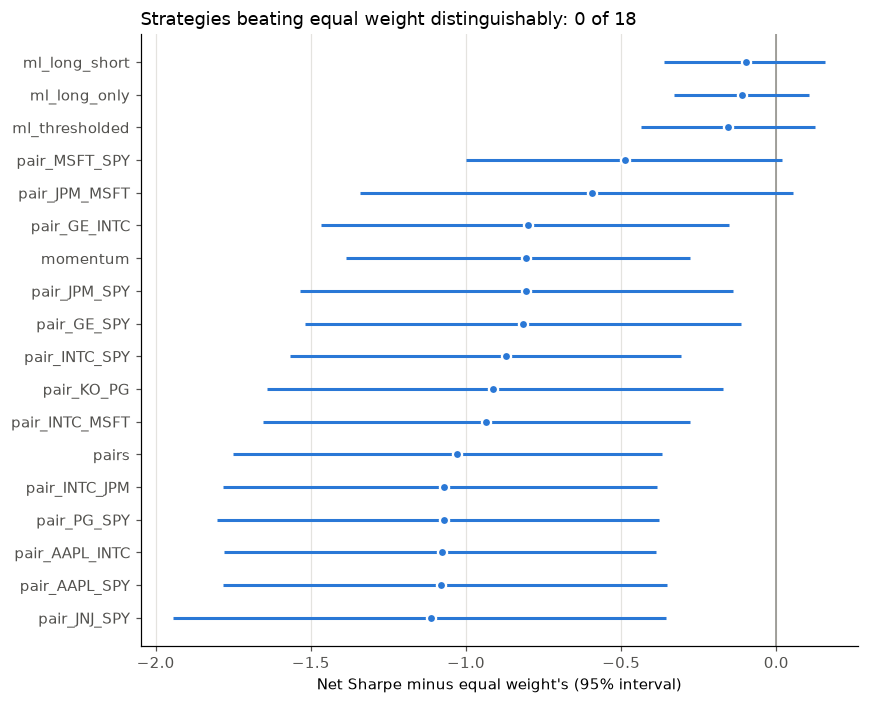

In [7]:
# One series, so no legend: the title names it. Zero is the equal-weight book.
order = candidates.sort_values(f"sharpe_net_vs_{REFERENCE}")
y = np.arange(len(order))
fig = Figure(figsize=(8, 6.5), dpi=110)
ax = fig.subplots()
ax.axvline(0, color=GREY, linewidth=1)
ax.hlines(y, order["vs_reference_low"], order["vs_reference_high"], color=BLUE, linewidth=2)
ax.plot(order[f"sharpe_net_vs_{REFERENCE}"], y, "o", color=BLUE, markersize=6,
        markeredgecolor="white", markeredgewidth=1.5)
ax.set_yticks(y, order.index)
ax.set_xlabel("Net Sharpe minus equal weight's (95% interval)")
ax.set_title(
    f"Strategies beating equal weight distinguishably: {len(ahead)} of {len(candidates)}", loc="left"
)
ax.grid(axis="x", color=SHADE)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=DARK_GREY)
fig.tight_layout()
fig

### Allocations

Monthly-rebalanced allocations of the same eleven stocks, one development path, compared
with monthly equal weight.

In [8]:
data.portfolio[["sharpe_net", "vs_equal_weight", "vs_equal_weight_low", "vs_equal_weight_high",
                "p_beat_equal_weight", "max_drawdown_net"]]

,sharpe_net,vs_equal_weight,vs_equal_weight_low,vs_equal_weight_high,p_beat_equal_weight,max_drawdown_net
allocation,,,,,,
equal_weight,0.7244,0.0000,0.0000,0.0000,0.000,-0.4605
inverse_volatility,0.7412,0.0168,-0.0438,0.0822,0.718,-0.4246
risk_parity,0.7491,0.0247,-0.0313,0.0833,0.822,-0.4204
minimum_variance,0.7851,0.0607,-0.2107,0.3153,0.708,-0.3308
maximum_sharpe,0.6040,-0.1204,-0.4137,0.1371,0.176,-0.4022


## 4 · How many trials

Every experiment is in `reports/trial_log.csv`. Only selection trials count towards N
(research, backtest and the notebook experiments); benchmarks and diagnostics were never
candidates. The 42 notebook records are historical: parsed from the notebooks' saved
outputs, code not recoverable, and none has a development Sharpe ratio.

In [9]:
trials = trial_summary(data.trial_log)
trials["by_kind"]

,executions,unique_trials,names,counts_towards_N
kind,,,,
backtest,102,54,23,True
benchmark,13,5,3,False
diagnostic,15,12,11,False
notebook,42,42,42,True
research,3,2,1,True


In [10]:
trials["provenance"]

executions
kind     code_version                      
backtest 6433345-dirty                   18
         70fb742-dirty                    8
         c8ff091-dirty                   36
         e69b687-dirty                    4
         f80baef-dirty                   36
notebook notebook, not recorded          42
research 6433345-dirty                    1
         unrecorded                       2

In [11]:
trials["scenarios"]

,n_trials,pipeline,notebook,rule
scenario,,,,
all_fingerprints,98,56,42,"every distinct (kind, fingerprint), including ..."
distinct_choices,66,24,42,versions of one named trial merged: a correcte...
distinct_less_overlap,63,24,39,"as distinct_choices, less 3 notebook experimen..."
pipeline_only,24,24,0,pipeline trials only; ignores the notebook sea...


## 5 · Luck threshold and deflated Sharpe ratio

V[SR] is the variance of the annual net Sharpe ratios of the candidates in the saved
results (checked against the trial log). The luck threshold is the Sharpe ratio the best of
N unskilled trials would be expected to reach; the DSR is the probability, under the
model's assumptions, that the selected strategy's true Sharpe over the sample exceeded it.
It is not a probability of future profit.

In [12]:
tables = deflation(data)
top = tables["headline"]
assert top["dsr"] < 0.95, "the prose below assumes no DSR reaches 0.95; re-read it"
pd.Series(top, name="pre-registered headline").to_frame()

,pre-registered headline
selected,allocation_minimum_variance
n_trials,98
variance_strategies_annual,0.1175
variance_strategies_and_allocations_annual,0.1582
variance_every_backtest_fingerprint_annual,0.1216
variance_own_sampling_variance_annual,0.0715
variance_used,strategies_and_allocations
variance_used_annual,0.1582
sharpe_period,0.0495
n,3504


The headline follows the rules written in `reports/methodology/trial_accounting.md`
before any DSR was computed: N counts every distinct fingerprint, superseded versions
included, and V[SR] is the largest of the pre-registered options (the trial log's
variance, the current candidates' with and without the allocations, and the selected
strategy's own sampling variance), which gives the highest luck threshold.

**Correlated trials.** The candidates' daily net returns are clustered (average linkage,
cut at correlation 0.5), and the participation ratio of their correlation matrix gives a
second estimate. Both put the effective number of independent candidates well below the
raw count. These estimates sit beside the headline; they do not replace it.

In [13]:
tables["effective"]

,candidates,independent_candidates,other_trials,n_trials,sharpe_annual,luck_threshold_annual,psr_vs_zero,dsr,min_track_record_years
estimate,,,,,,,,,
clusters,22.0,15.0000,41.0,56.0,0.7851,0.9224,0.9983,0.3039,inf
participation,22.0,8.1998,41.0,49.0,0.7851,0.9022,0.9983,0.3308,inf


### Every scenario

All four trial counts against each V[SR] scenario, so no single choice decides the
conclusion.

In [14]:
tables["variances"]

,candidates,variance_annual,best,best_sharpe_annual,source,variance_period
scenario,,,,,,
strategies,18,0.1175,ml_long_short,0.759,saved development results,0.0005
strategies_and_allocations,22,0.1582,allocation_minimum_variance,0.7851,saved development results,0.0006
every_backtest_fingerprint,54,0.1216,allocation_minimum_variance,0.7851,"trial log, superseded versions included",0.0005


In [15]:
grid = tables["grid"]
grid[["variance_scenario", "count_scenario", "selected", "n_trials", "sharpe_annual",
      "luck_threshold_annual", "psr_vs_zero", "dsr", "skew", "kurtosis", "n", "paths"]]

,variance_scenario,count_scenario,selected,n_trials,sharpe_annual,luck_threshold_annual,psr_vs_zero,dsr,skew,kurtosis,n,paths
0,strategies,all_fingerprints,ml_long_short,98,0.7590,0.8650,0.9980,0.3435,0.2119,14.3887,3635,5
1,strategies,distinct_choices,ml_long_short,66,0.7590,0.8160,0.9980,0.4141,0.2119,14.3887,3635,5
2,strategies,distinct_less_overlap,ml_long_short,63,0.7590,0.8101,0.9980,0.4229,0.2119,14.3887,3635,5
3,strategies,pipeline_only,ml_long_short,24,0.7590,0.6786,0.9980,0.6201,0.2119,14.3887,3635,5
4,strategies_and_allocations,all_fingerprints,allocation_minimum_variance,98,0.7851,1.0036,0.9983,0.2070,0.3668,20.8928,3504,1
5,strategies_and_allocations,distinct_choices,allocation_minimum_variance,66,0.7851,0.9468,0.9983,0.2727,0.3668,20.8928,3504,1
6,strategies_and_allocations,distinct_less_overlap,allocation_minimum_variance,63,0.7851,0.9399,0.9983,0.2813,0.3668,20.8928,3504,1
7,strategies_and_allocations,pipeline_only,allocation_minimum_variance,24,0.7851,0.7873,0.9983,0.4967,0.3668,20.8928,3504,1
8,every_backtest_fingerprint,all_fingerprints,allocation_minimum_variance,98,0.7851,0.8800,0.9983,0.3614,0.3668,20.8928,3504,1
9,every_backtest_fingerprint,distinct_choices,allocation_minimum_variance,66,0.7851,0.8302,0.9983,0.4331,0.3668,20.8928,3504,1


In [16]:
tables["crossings"]

,selected,N where DSR < 0.95,N where DSR < 0.5
variance_scenario,,,
strategies,ml_long_short,4,43
strategies_and_allocations,allocation_minimum_variance,4,24
every_backtest_fingerprint,allocation_minimum_variance,4,47


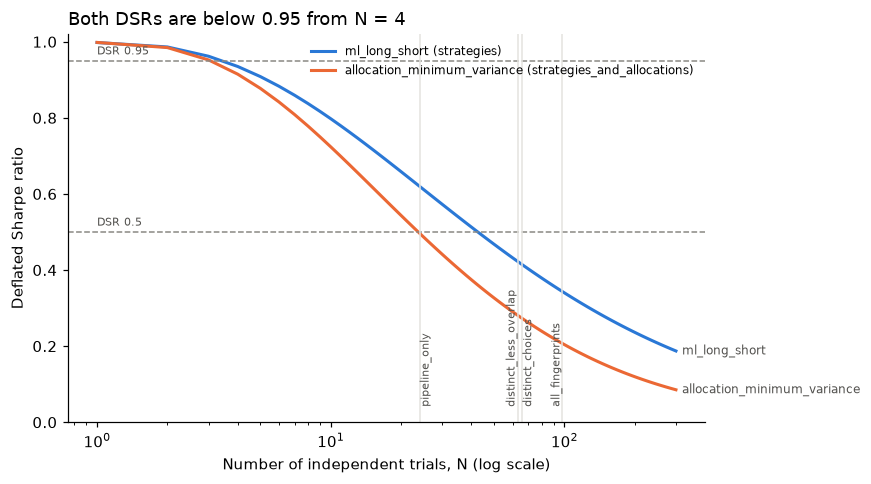

In [17]:
# DSR against N for each variance scenario's selected strategy; the four count
# scenarios are marked. One y-axis (probability), two series, labelled directly.
variances = tables["variances"].dropna(subset=["best"])
n_grid = np.unique(np.geomspace(1, 300, 120).astype(int))
fig = Figure(figsize=(8, 4.5), dpi=110)
ax = fig.subplots()
for colour, (scenario, row) in zip((BLUE, ORANGE), variances.iterrows()):
    moments = path_moments(paths(row["best"]))
    curve = [deflate(moments, int(n), float(row["variance_period"]))["dsr"] for n in n_grid]
    ax.plot(n_grid, curve, color=colour, linewidth=2, label=f"{row['best']} ({scenario})")
    ax.annotate(row["best"], (n_grid[-1], curve[-1]), xytext=(4, 0),
                textcoords="offset points", va="center", color=DARK_GREY, fontsize=8)
for level in (0.95, 0.5):
    ax.axhline(level, color=GREY, linewidth=1, linestyle="--")
    ax.text(1, level + 0.01, f"DSR {level}", va="bottom", fontsize=7, color=DARK_GREY)
# Neighbouring counts (63 and 66) get their labels on opposite sides of their lines.
for i, (scenario, n) in enumerate(trials["scenarios"]["n_trials"].items()):
    ax.axvline(n, color=SHADE, linewidth=1)
    ax.text(n, 0.03, f" {scenario} ", rotation=90, va="bottom", ha="right" if i % 2 == 0 else "left",
            fontsize=7, color=DARK_GREY)
ax.set_xscale("log")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Number of independent trials, N (log scale)")
ax.set_ylabel("Deflated Sharpe ratio")
first_below = int(tables["crossings"]["N where DSR < 0.95"].max())
ax.set_title(f"Both DSRs are below 0.95 from N = {first_below}", loc="left")
ax.legend(frameon=False, loc="upper right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig

**Reading the DSR.** The trials are far from independent: the ML books share one model's
forecasts, the pairs share legs, the allocations hold the same eleven stocks. Correlated
trials act like fewer independent ones, so the effective N is below every count above and
these DSRs lean conservative. Even so, the selected Sharpe ratios fall below 0.95 at a
handful of independent trials, so the conclusion does not hinge on which count is right.

## 6 · Reconciliation with notebook 4

Notebook 4 traded SPY alone on a random forest's daily forecast and found that costs
destroyed the long/short rule while the long-only rule held up. Its code is re-run here on
the development years only (bars cut at 2019-12-31 before the model code runs), so the
comparison never touches the holdout.

In [18]:
RECONCILIATION = ROOT / "reports" / "results" / "reconciliation"
forecast = pd.read_csv(RECONCILIATION / "notebook4_forecast.csv", index_col=0)["value"]
rules = pd.read_csv(RECONCILIATION / "notebook4_rules.csv", index_col=0)
steps = pd.read_csv(RECONCILIATION / "notebook4_costs.csv", index_col=0)
signals = pd.read_csv(RECONCILIATION / "notebook4_signals.csv", index_col=0)["value"]

assert pd.Timestamp(forecast["last_prediction"]) < holdout
print(f"Notebook 4 forecasts {forecast['first_prediction']} to {forecast['last_prediction']}: "
      f"IC {float(forecast['ic']):+.4f}, hit rate {float(forecast['hit_rate']):.4f}")
rules[["sharpe_gross", "sharpe_net", "sharpe_lost", "turnover_per_year"]]

Notebook 4 forecasts 2008-01-11 to 2019-12-30: IC +0.0210, hit rate 0.5065


,sharpe_gross,sharpe_net,sharpe_lost,turnover_per_year
rule,,,,
binary long/short,0.3258,-0.0068,0.3326,130.0996
scaled by conviction,0.2561,-0.1253,0.3814,114.6381
long only,0.5082,0.3167,0.1915,65.0916
buy and hold,0.5581,0.5579,0.0002,0.0837


In [19]:
# Notebook 4's findings, each checked against the development-years rerun and the pipeline.
pipeline = comparison.loc[["ml_long_short", "ml_long_only"], ["sharpe_net", "sharpe_lost_to_costs",
                                                             "turnover_annual", "exposure_net_mean"]]
checks = pd.Series({
    "nb4: long only beats long/short net of costs":
        rules.loc["long only", "sharpe_net"] > rules.loc["binary long/short", "sharpe_net"],
    "nb4: costs remove most of the long/short Sharpe":
        rules.loc["binary long/short", "sharpe_lost"] > rules.loc["binary long/short", "sharpe_gross"] / 2,
    "nb4: the forecast's IC is small and positive": 0 < float(forecast["ic"]) < 0.05,
    "pipeline: IC is small and positive too": 0 < data.research.metrics["ic_mean"] < 0.05,
    "pipeline: costs take far less Sharpe than in nb4":
        float(pipeline.loc["ml_long_short", "sharpe_lost_to_costs"]) < rules.loc["binary long/short", "sharpe_lost"],
    "pipeline: forecasts flip sign less often than nb4's":
        signals["Phase 6 SPY forecast changes sign"] < signals["notebook SPY forecast changes sign"],
}, name="holds")
display(pipeline)
checks.to_frame()

,sharpe_net,sharpe_lost_to_costs,turnover_annual,exposure_net_mean
strategy,,,,
ml_long_short,0.7590,0.0582,17.7096,0.9244
ml_long_only,0.7477,0.0274,8.8903,0.9580


,holds
nb4: long only beats long/short net of costs,True
nb4: costs remove most of the long/short Sharpe,True
nb4: the forecast's IC is small and positive,True
pipeline: IC is small and positive too,True
pipeline: costs take far less Sharpe than in nb4,True
pipeline: forecasts flip sign less often than nb4's,True


In [20]:
steps[["sharpe_gross", "sharpe_net", "sharpe_lost", "turnover_per_year", "days"]]

,sharpe_gross,sharpe_net,sharpe_lost,turnover_per_year,days
step,,,,,
0 notebook code,0.3258,-0.0068,0.3326,130.0996,3012
"1 same positions, Phase 6 engine",0.3227,-0.0083,0.3310,130.2469,3012
2 + borrow 0.5%/yr,0.3227,-0.0176,0.3404,130.2469,3012
3 + one-bar delay,0.5292,0.1875,0.3417,130.1250,3012
"4 Phase 6 forecasts, SPY only",0.5359,0.5020,0.0339,12.2811,3635
"5 Phase 6 book, 11 tickers, path 0",0.9400,0.8720,0.0680,20.0820,3635


**What reconciles and why.** The forecasting result agrees: both IC estimates are small
and positive. The cost result differs for a traceable reason, attributed step by step
above. Notebook 4's forecast changed sign on about a quarter of days, so its long/short
rule traded constantly and lost about a third of a Sharpe ratio to costs. The pipeline's
forecasts are positive on almost every day and rarely flip, so its "long/short" book is
mostly long, trades less and loses little to costs. That is also why its long/short and
long-only books end up nearly identical. Neither changes the main finding: no strategy
beats holding the eleven stocks in equal weight by a margin the data can distinguish.

## 7 · Limitations

- **Survivorship.** Eleven tickers known to have survived to the end of the sample;
  every long book is flattered by it.
- **One model.** Every ML book trades the same forecasts, so the books are not
  independent evidence.
- **Trial dependence.** The DSR assumes independent trials. These are not, so the raw
  counts do not show that the trials were independent.
- **Historical notebook trials** enter N but not V[SR]: their outputs give no
  development Sharpe ratio.
- **Holdout.** Not evaluated. The full report is `reports/research_report.md`
  (`make report`).